# 🌍 AI for a Sustainable Future
## Hands-on: Predicting CO₂ emissions in five countries

**Dr. Medhasree Ghosh · Future Computing Group(FCG), University of Oulu**

Imagine that you are an environmental analyst. You have historical emissions data and want to estimate what may happen next year. How do different forecasting methods behave? What happens if recent emissions change?

### What we will do

| Part | Activity | Suggested time |
|---|---|---:|
| 1 | Load real public data, inspect five countries and their individual trends | 5 min |
| 2 | Learn the intuition behind seven forecasting models and prepare the experiment | 5 min |
| 3 | Train, predict, compare errors and see actual vs predicted curves | 12 min |
| 4 | Change India's recent history and explore GRU predictions | 8 min |

**Countries:** India, Finland, Denmark, Iran and Canada.

**Models:** ARIMA, SARIMA, VAR (statistical methods); RNN, LSTM, GRU and 1D CNN (deep learning). We also include a simple last-year baseline to help interpret the results.

**Data:** [Our World in Data CO₂ dataset and codebook](https://github.com/owid/co2-data). By default, the target is annual territorial fossil-fuel and industrial CO₂ emissions in **million tonnes (Mt CO₂)**, excluding land-use change. This is not total greenhouse gases (CO₂e), nor atmospheric CO₂ concentration. The same notebook can also model tonnes of CO₂ per person.

## ▶️ How to run this notebook

1. Download this `.ipynb` file. Open [Google Colab](https://colab.research.google.com/).
2. Choose **File → Upload notebook** and select this file.
3. Connect to a runtime. A normal **CPU runtime is sufficient**; no GPU or API key is required.
4. Run **Runtime → Run all** (or press the play button next to each code cell in order).
5. Wait while the models train. Progress messages will show each country and model. For a live lecture, run the notebook once before the session and keep the runtime open.
6. To demonstrate the India experiment, change only the values in the last section (e.g., `CHANGE_PERCENT = -20`) and rerun that section's code cells. No need to train again.

The notebook already includes a real OWID snapshot downloaded on 16 November 2026, covering 1960–2025 for the five countries. This makes the live demo independent of a dataset download. To refresh from OWID, set `REFRESH_FROM_WEB = True` in Step 2. If needed, you can also download `owid-co2-data.csv` from the linked repository, upload it in Colab, and set `LOCAL_CSV = "/content/owid-co2-data.csv"`. Dependencies may require internet if they are missing.

**Note:** model scores are computed from actual reported data, never fabricated. The latest available common year is detected automatically. The dataset contains emissions estimates that may be revised.

## 1. Setup: import the tools

This cell checks whether the required libraries are available, then imports them. If a library is missing, it installs it. PyTorch runs the four neural networks; statsmodels runs the statistical models; pandas and matplotlib help us explore and visualize the data.

In [ ]:
import sys, subprocess, importlib.util

required = {"numpy":"numpy", "pandas":"pandas", "matplotlib":"matplotlib",
            "statsmodels":"statsmodels", "torch":"torch"}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing libraries:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import warnings
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import torch
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)  # Small annual datasets are fast on CPU

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
COUNTRIES = ["India", "Finland", "Denmark", "Iran", "Canada"]
COLORS = dict(zip(COUNTRIES, ["#0F847B", "#557CA8", "#D99C3D", "#C96F61", "#8068B0"]))
MODEL_COLORS = {"Persistence":"#777777", "ARIMA":"#5679AA", "SARIMA":"#9274B2",
                "VAR":"#D89B42", "RNN":"#70A7BF", "LSTM":"#C96977",
                "GRU":"#0F847B", "CNN":"#527D65"}
MODELS = ["ARIMA", "SARIMA", "VAR", "RNN", "LSTM", "GRU", "CNN"]
ALL_MODELS = ["Persistence", *MODELS]
NEURAL_MODELS = ["RNN", "LSTM", "GRU", "CNN"]
print("Setup complete. We are ready to load the data.")

Setup complete. We are ready to load the data.


## 2. Download and prepare country-year data

We use a common span of consecutive years for all five countries. This makes the comparisons fair and also allows VAR to learn how the five series move together. No missing emission values are invented: after selecting the years, we keep the latest continuous interval with valid positive values for every country.

You can change the target or earliest year using the configuration below. Five-year seasonal terms are an **illustrative hypothesis**, not an established physical cycle in annual CO₂ emissions.

In [ ]:
#@title Offline backup: real OWID data (run once; no changes needed)
# This compressed CSV contains only India, Finland, Denmark, Iran and Canada.
# Source: https://github.com/owid/co2-data (downloaded 16 November 2026).
import base64, gzip, io
SNAPSHOT = "H4sIAPQP+2oC/12ZzY42NQ6F91xLqZT/OOsZjTRXgVrAAs3MB/oEC+5+nuPqrjgsoCHnTeKc2Md26qff/vz2x/e/rr9++fh+/fRb0T8//v7L9x9/+vj91z8+fvjHx7ePnz+uvEbiX/XupVw53ZZLgLJDtTdB3WaAylVSv2frV8536jVAFWjdD9DinHaVypzFTuUuqQWoX6WnO6cuaKYeoAE0MUKI1bjRvMpcd17ryvUeFhC7akrszk7tbjMHaAG1O+lsQNHwma5aEwsxq9+tBPtmvmqDgmKCeg8kzXLVYXcdVx53D8ed9apTh5mO9BGgBsSZ+Cuoxp36VW3ck79AM4VTzXG1VO5WMWLe+dhrXg0OzLKg1sKBp10c5S4icN5jRdPX1To3YVho9xhhliWgfC8T0kpgiS1aXVjhy0WfgLdWcKHmB57hUFYxr9+W/FB1BBussVy9SxZiM5BkHSTfo/mk0QITNvy4WRAOdawHE1xiKU5tiUeCiM7NL78pG/FMEDE408gPs8H9lojAycyt6NEpFkzgtNZ9wRQjBxdvo90jOVRThOBi9Ls2E5TjVS24wKEt+6wWj7UgY5W75ofbY69xdeItiXaMT3HBefWCWyjicIuyAmRXh90pNubpgsRTbwRA9gVtH7mklK4+GCMe8ItqNUD56hBlzb1z1RGgwiyOzPkEbTOA6tWt3qk2XzDHBdvVpxGpz4JxUgeBjPX4YOsBggyisXSHaotWQAYUpuqXbHE9uJj4kflOJccDiwu2mn5bqQYow0XnLoZDxXKA4GLA+3iuP1uAikP9ucgcacrVbXd9BMoRggv8yRSpxNHWH6DuC+a+BI04CS5w+FZ9UunRQLgYBFX2SVxMgB4yrDVXwYgsv5D5OSnPDZXkjqZEUflBuBACuyP6VqagFQkk48jPpiDissf1oKJlosPXiwBEIMRJ490CrwUaGjeen2TQfvjnL9/+9/H9P0+GKwZ3/VIoWkSQdQk+wCATBABRh0zuEf8iDgOCqi/d24W7IhQBIXozbC+QiZAFhOAtLmR2s2dEEDLjqk0JNh0WoGNEM8daSOmxGhcENUi+kvJhGxc07tWGUu9ocSNy22AHqWJh7oqQAhf6lyfsFZkjt5F6WxbS07FeFSIrBbVoOUmtc2nL7TvJm7qku1Y/7qzxKkhunbgtvlfjygM0ZXsmPIAsH3vBxWKW2z7SYfu6BjQ5F+u4XHIbk9LySb1GbkluUnSkYqFTESg6VC5uebVIhZIbuocYcVOHR5DbWG04snI8Er6ICbN6kTTO5ZyIqVASEfFIRH+XIDoRtRxbmZidT6U2zllLPkZ+w4p23BS5jUO1x5MoLSKUL/Tmsx5DQSJUZEUtfvXlcCVOyk316bafVqD9Soj4jRYsx15dNzW6H2seZJCdZruX9KHUA8An+lMKoc52LGdargiSa0aWlNnsayek6YWezIZrJuci3NVnYuN+H5bqMakI6g/rtbYIORXjqY/DVT15rd/Z91kH0BXYqCUXRUaPyJC7dE1Z4QafnMa1k6WkH6fZLhOF4mRhWgTcH6xn1MhaNICM1lRPCxgjAlQ6uoGJHK4WGSCdIYc2JJRER0RU85EdK0h0IE9mlZID3ZHsHkiX7OYsJM8DGVTZCiKQdho9Kc3RGal7yvGgqKoQpfAbwYqImgBUAaCWCBRPFVgOP8d4vsqSwFxSyrg9SQykwyZIiqSRw4pqcSSeTBJ9AxUGSURQU98VEfogvLBrTur2w79+/fbfj28/f7ZpRAJXQEM2S0S8kzFCBaSuiHgh0R0ZuFpAqsqtVbRPthYRbFNphZOAH4jbNis+T0o49hlirbEPddBh2hSgCOJu5jGFuymuFBBxGr3kHVTPeGFOcTX1Z1Bt8s9+HEftmST28uCOAHV49dhdXk8HpCoKPFcS1dGA2TzzVu+H0wmRyPHM4Ul5HchQtLXkSmAz3hzy2pOzI2mmDQwQMQrZn010Po6kwvNWQnIVC4jSFwFavYtGjgKStVwurgbEZIScCAnFcgcOSFVxoh6frHPcnlqzcq/kBU08rLIX4mWuiKhChIbMTsN5IB9EyLOXPYddp+GevfJ6Zh0UmfPQs+vlirwqeyEJereA+YO85ZKdl6coBC9CKjpJW9VLkBGJXaq/EQSnXOV3gJpyylQlBMH1mNV1rFw859WDJwUEZDyzcIAIIWR6G/B0mA9XWl7T1P7kr3wc2fOXTaewBjae/EUo5aeKC8Z7AmMvf+Ch/ek5QkVpFCcX1NOxIMJN0Tqesv1AIEOhY4KyHVB3K0b/exh4DtMzyfQKFK+LEGSokZqCRhCdJ4uZxvxY9Zi1dMmruGeoUNoQiUzEr/wUfxFRZ0ZafornHNdTZ8a9Ewiqk6Lpasyy9z1PYg6Ia8VA6r0vikhXysy4myq2w4ShOaUXl7Fjn6k5g5uX9M2I6O0C7VWQllUishSkTTo6LN46qQwdnVnNjZV46TBW1ddXR445essiiQjpxz3w40rxrdqeVHKs1pQAlxp5T6YB6UKy2jxvOf797edfv14cvYC1C/lAjF5AgZLUbzA+9zCOS7LQkw7jFhYiejh8Qlkov6j+X0B9IxL97ABfL6AHI8J/aKmaw9bq1JHn7EtB1wuoT1fMV58RrNJjAcUIAqXazzZAMBneb+bANpf8lc2p+Dugd1avUQT0vfnUK6u/mAgY+4D8svjLpp9j7M2n0rfUy2dsa5GMUp9OifEVthj+8mpLK7UUAHI32iCJSi6vL2BUL9DqVLW8yeVcxaqqcQFlA2SsslQHdAF1H4OEhcsgMr7H2OP4YVW6cqNG3QBuqNe47ivZPh+5Sq+wdMoObEL0iphIIF0Hl0+/AGFIeZib9uht34ZeEP3GtRRV6gbQokTea1pqpM2I5yjO50vpofILUIoyhMgZGXPPUHvFNTW/DijeAIKsZmhpxqwBICYhN1d5FYloA4R+pjZ9lhphj35NvfEU3dNcwapxWVn+KuivtRuYl+mVya9DHcALoEhs7hzaCBNQRFcfXcdKX1t4Nlp6DMzFgbmBfBEg3LjIXXu4XBzdCzX9vm9AeRoXeWJj5bCSigXzUlRID3OUHi2rRrzU5tWNEOVlaTX+A4kNiJ6nFu6ALOtxJW+EOG9L61zqKtsGiPOhhytMDMrg2SePqWBzZBumIoYbuvXAd++FIIk8QQJUKiPBhJWqX5deCIS0bRWJBwGYT8N6jzo2QqSXqtekJWRukkk82I9Wq1/FhwJCrOsjgRdntOCbF9JH0avpkNyhaWEfon0gTs0Zs7mtVhPV1F5MX61sAtRGjSmNm77adhi1UaaI0EFXMFqJh/pEsniptt0AEZ+nf4wRYGEKXWRJFTUbjrDL949vT+KpIlNHoRR+h7OGs5wDJss77MnQ9DVIeeEdpl5W6eBH2z9u6gzUamU9HH2NdhXkerXFjryHKYWqZjPcxl55qkJKS7/ufQ8TfOKEm6Bu2oehLKdV5I+G29cwScaoUvRMSctV32HiTjUbzRUJsb/DanJgikRZ1Ye846pLcVQiiGjZtswnsQ41DaTul0LdNGI61bxhzf49fKgvwq+wte1xPUnrLUHDwRx9XoNGLZ736PJRJlzeWnyNm+oI9eO6ZtvMKFhwTKsa72OPq46AyfVQ9l6HqYzQ1yT11jm/w82HK6peNOkdVw1B7a6Ug7Tv33PWpoqdALxn3+PTOTDTOta2OfpuQIVGLqj+ofRrXPVD9ljkrtI7TjIpCf/Qx0OO9dLA/EICqN7l76tCZIqe5PWm4l3x1zilg9y9atyUdD/HMW/oQOr8y9zjHAfFLktvBbW8NPD/Rd8Jhn5f95XLfYe+omg8b9qWvsnqS4qeQ2wvvzxx96pXmlE/WfMMUsnCKpPR+N7ecdjC7wvdhyrR+Y7rIUqarwp1dnvHFa76kElj6s9dX+PN039SLKL3+/c4Hwo1vTruX7Q9T3AJtUF4x3a25wUuLbWLXk1vO9Xa07noBVMvIO/48i8bjX3m9p7Pr0kTtdJ7Wd7nUsOiPoxIldqPdxxeFiVu1u/1cflrXO+O018iZrRfdqNQyTuFVfb6HS3SFz2tM8u2R70r/DyfQOw9l17glp6B1PJ4nvwcp8/ATTRvSgfe8UUbCW/NP5jUl3+SxNSLhL6JtE0/GWKS1LupB7JND1o5TZ+qNa4vB1/jmEHaSP66nUZ5x+mU9M1FhQVBtMfZj66xoDSM41b/Bz58Kj4oIQAA"
def load_embedded_snapshot():
    return pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(SNAPSHOT))))

In [ ]:
# ---- EASY SETTINGS: change these only if you want ----
TARGET = "co2"             # "co2" = total Mt; "co2_per_capita" = tonnes/person
START_YEAR = 1960          # Earliest candidate year
TEST_YEARS = 8             # Last 8 observed years held out
LOOKBACK = 5               # Past 5 annual changes used by the neural networks
SEASONAL_PERIOD = 5        # Illustrative multi-year SARIMA cycle
EPOCHS = 100               # Increase for experiments, not for the live demo
HIDDEN_SIZE = 24
LOCAL_CSV = ""             # Optional path to a locally downloaded OWID or snapshot CSV
REFRESH_FROM_WEB = False   # True = fetch latest OWID data; False = embedded snapshot

if TARGET not in {"co2", "co2_per_capita"}:
    raise ValueError("Choose co2 or co2_per_capita.")
UNIT = "Mt CO₂" if TARGET == "co2" else "t CO₂/person"
DATA_URL = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
if LOCAL_CSV:
    raw = pd.read_csv(LOCAL_CSV, usecols=["country","year",TARGET])
    print("Data source: local CSV:", LOCAL_CSV)
elif REFRESH_FROM_WEB:
    try:
        raw = pd.read_csv(DATA_URL, usecols=["country","year",TARGET])
        print("Data source: live OWID CSV")
    except Exception as exc:
        print("Live download failed; using real embedded OWID snapshot:", exc)
        raw = load_embedded_snapshot()
else:
    raw = load_embedded_snapshot()
    print("Data source: embedded OWID snapshot (downloaded 16 November 2026)")

filtered = raw[raw["country"].isin(COUNTRIES)].copy()
filtered["year"] = pd.to_numeric(filtered["year"], errors="coerce")
filtered[TARGET] = pd.to_numeric(filtered[TARGET], errors="coerce")
filtered = filtered.dropna(subset=["year"]).sort_values(["country","year"])
filtered["year"] = filtered["year"].astype(int)
if filtered.duplicated(["country","year"]).any():
    raise ValueError("Duplicate country-year observations found; inspect the input CSV.")
print("Available observations before choosing a common period:")
display(filtered.loc[filtered[TARGET].gt(0)].groupby("country")["year"]
        .agg(First_year="min", Last_year="max", Observations="count")
        .reindex(COUNTRIES))

wide = filtered.pivot(index="year", columns="country", values=TARGET).reindex(columns=COUNTRIES)
wide = wide.loc[wide.index >= START_YEAR]
if wide.empty:
    raise ValueError("No rows after START_YEAR.")
wide = wide.reindex(range(int(wide.index.min()), int(wide.index.max())+1))
wide = wide.where(np.isfinite(wide) & wide.gt(0))
complete = wide.dropna()
if complete.empty:
    raise ValueError("No common positive observations for the chosen countries.")
end_year = int(complete.index.max())
start_year = end_year
while start_year-1 in complete.index:
    start_year -= 1
data = complete.loc[start_year:end_year, COUNTRIES].astype(float)
data.index.name = "year"
if len(data) < TEST_YEARS + max(30, LOOKBACK+10, 3*SEASONAL_PERIOD):
    raise ValueError("Not enough contiguous annual observations. Lower START_YEAR or inspect the data.")

print(f"Common period: {start_year}–{end_year} | {len(data)} annual observations per country")
print(f"Unit: {UNIT} | Next unobserved year in the dataset: {end_year+1}")
display(data.tail().round(3))
snapshot = data.reset_index().melt(id_vars="year", var_name="country", value_name=TARGET)
snapshot.to_csv(f"five_country_{TARGET}_snapshot.csv", index=False)

Data source: embedded OWID snapshot (downloaded 16 November 2026)
Available observations before choosing a common period:


,First_year,Last_year,Observations
country,,,
India,1960,2025,66
Finland,1960,2025,66
Denmark,1960,2025,66
Iran,1960,2025,66
Canada,1960,2025,66


Common period: 1960–2025 | 66 annual observations per country
Unit: Mt CO₂ | Next unobserved year in the dataset: 2026


country,India,Finland,Denmark,Iran,Canada
year,,,,,
2021,2670.357,37.823,29.604,785.588,535.827
2022,2821.410,36.333,29.551,782.288,545.727
2023,3049.351,31.874,27.446,821.069,541.140
2024,3175.552,29.903,27.027,842.602,540.000
2025,3203.406,29.122,24.356,855.278,547.319


## 3. Explore: what do the countries' emission histories look like?

First, look at all five countries on the same scale. Then look at each separately because India may be much larger in absolute emissions than the smaller Nordic countries. A separate scale makes the local trend visible; compare the axis labels carefully.

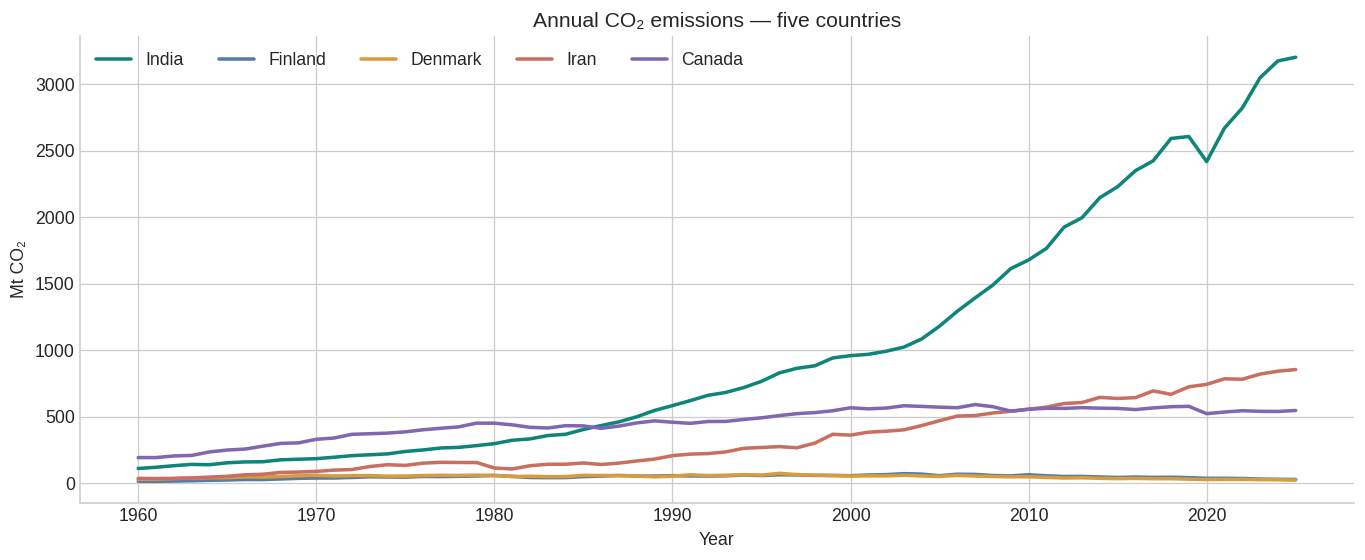

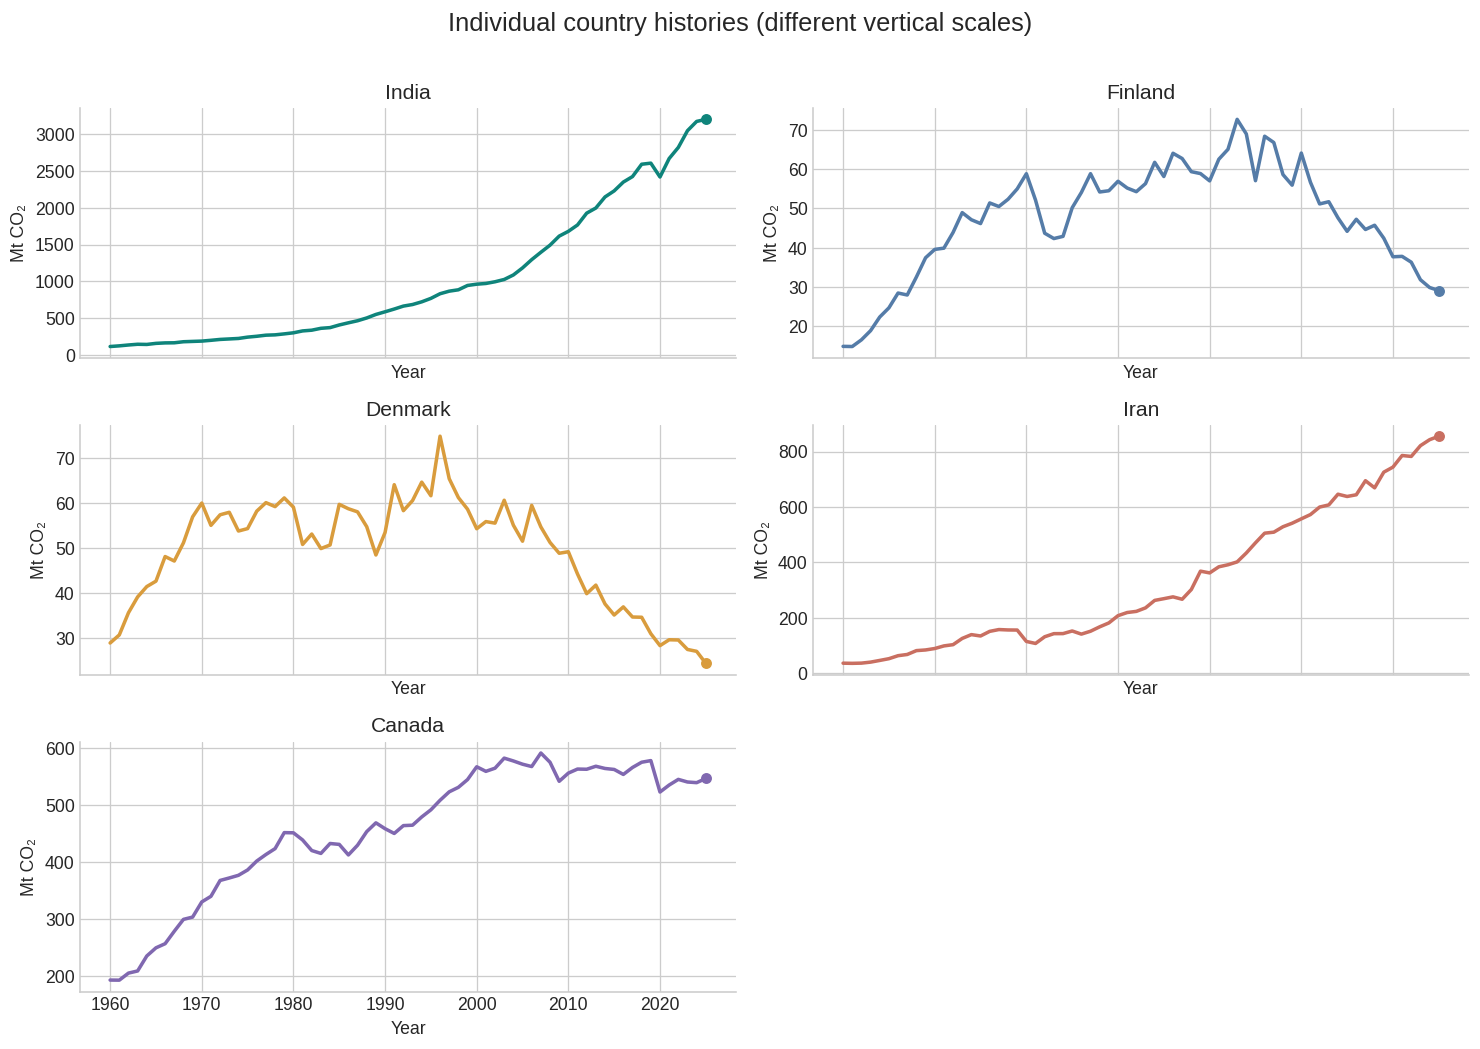

In [ ]:
fig, ax = plt.subplots(figsize=(12,5))
for country in COUNTRIES:
    ax.plot(data.index, data[country], label=country, color=COLORS[country], lw=2.2)
ax.set(title="Annual CO₂ emissions — five countries", xlabel="Year", ylabel=UNIT)
ax.legend(ncol=5, loc="upper left")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 2, figsize=(13,9), sharex=True)
for ax, country in zip(axes.flat, COUNTRIES):
    ax.plot(data.index, data[country], color=COLORS[country], lw=2.2)
    ax.scatter(end_year, data.loc[end_year,country], color=COLORS[country], s=34, zorder=3)
    ax.set(title=country, xlabel="Year", ylabel=UNIT)
axes.flat[-1].axis("off")
fig.suptitle("Individual country histories (different vertical scales)", fontsize=16, y=1.01)
plt.tight_layout(); plt.show()

**Observe:** Which countries are rising, decreasing, fluctuating or changing direction? Do countries with smaller total emissions necessarily have a lower per-person footprint? Try switching the target to `co2_per_capita` after the session.

## 4. How the seven models learn

| Model | Simple idea | Information used here |
|---|---|---|
| ARIMA | Learns from earlier values, changes and forecast errors | A country's history |
| SARIMA | ARIMA plus a repeating pattern | Same history plus a proposed 5-year cycle |
| VAR | Learns how several time series relate across time | All five countries' historical annual changes |
| RNN | Reads a sequence step-by-step, carrying a memory | Previous 5 annual changes |
| LSTM | Uses gates to keep or forget useful information | Previous 5 annual changes |
| GRU | Similar selective memory with a simpler gating design | Previous 5 annual changes |
| CNN | Slides a small pattern detector along the sequence | Previous 5 annual changes |
| Persistence | Predicts next year equals the last observed year | Last year's emission |

ARIMA, SARIMA and VAR are statistical models, not deep learning. LSTM and GRU are specialized recurrent neural networks. A **1D CNN** scans a sequence, unlike a conventional image CNN.

### A fair test: past → future

We reserve the latest eight observed years for testing. We fit model parameters and neural scaling **only on earlier training observations**. For each test year, the model predicts using actual values through the previous year; then that year's true observation becomes available for the next prediction. This is **rolling one-year-ahead evaluation**, not an eight-year prediction made in one shot.

For yearly data, SARIMA's seasonal period of 5 is an exploratory multi-year assumption. It is not twelve-month seasonality. We do not tune the period or model parameters based on the test set.

TRAIN: 1960–2017 (58 years)
TEST : 2018–2025 (8 years)
FORECAST AFTER EVALUATION: 2026


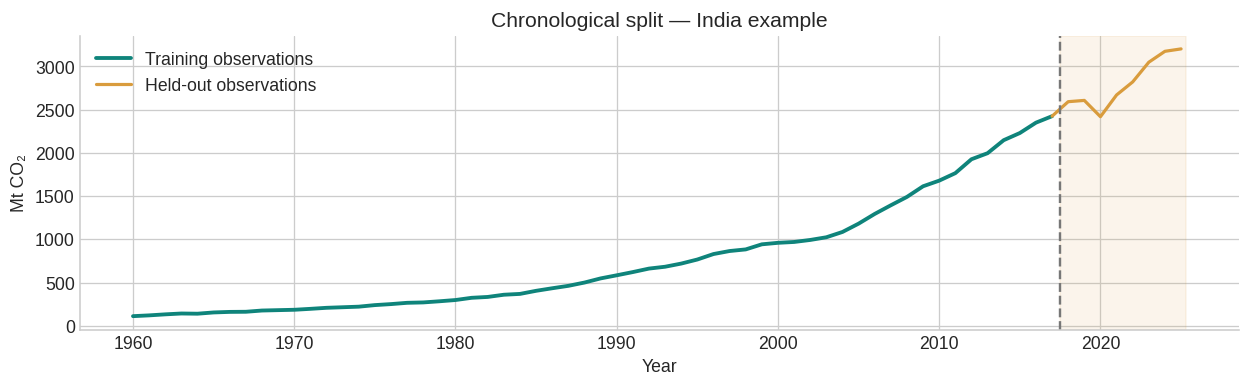

In [ ]:
years = data.index.to_numpy()
values = data.to_numpy()
split = len(data) - TEST_YEARS
train_years, test_years = years[:split], years[split:]
print(f"TRAIN: {train_years[0]}–{train_years[-1]} ({len(train_years)} years)")
print(f"TEST : {test_years[0]}–{test_years[-1]} ({len(test_years)} years)")
print(f"FORECAST AFTER EVALUATION: {years[-1]+1}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(years[:split], data["India"].iloc[:split], lw=2.4, color="#0F847B", label="Training observations")
ax.plot(years[split-1:], data["India"].iloc[split-1:], lw=2, color="#D99C3D", label="Held-out observations")
ax.axvline(test_years[0]-.5, ls="--", color="#777777")
ax.axvspan(test_years[0]-.5, years[-1]+.3, color="#D99C3D", alpha=.10)
ax.set(title="Chronological split — India example", xlabel="Year", ylabel=UNIT)
ax.legend(); plt.tight_layout(); plt.show()

## 5. Define the forecasting models (run these cells once)

**Behind the scenes:** Since countries differ greatly in scale, the neural models learn annual proportional changes (differences of logarithms), not raw levels. This makes it easier to learn changes in a rising or falling series. Predictions are converted back to original emission units for charts and error scores. ARIMA and SARIMA work on log levels; VAR jointly models the log changes. Positive values are required for the logarithms.

For beginners: you do not have to modify these functions. The two model-definition cells implement the ideas from the table.

In [ ]:
def fit_statistical(model_name, history):
    # Fit once on historical training data (no test observations).
    log_history = np.log(np.asarray(history, dtype=float))
    if model_name == "ARIMA":
        model = ARIMA(log_history, order=(1, 1, 1), trend="t")
    elif model_name == "SARIMA":
        model = SARIMAX(log_history, order=(1, 1, 1),
                        seasonal_order=(1, 0, 0, SEASONAL_PERIOD),
                        trend="c", enforce_stationarity=True,
                        enforce_invertibility=True)
    else:
        raise ValueError(model_name)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        result = model.fit() if model_name == "ARIMA" else model.fit(disp=False, maxiter=150)
    converged = bool(result.mle_retvals.get("converged", True))
    if not converged:
        print(f"  Note: {model_name} optimizer did not fully converge; interpret cautiously.")
    return result

def stat_one_step(result):
    prediction = float(np.exp(np.asarray(result.forecast(steps=1)).reshape(-1)[0]))
    if not np.isfinite(prediction):
        raise ValueError("Non-finite statistical forecast.")
    return prediction

def stat_backtest(model_name, series, split):
    result = fit_statistical(model_name, series[:split])
    preds = []
    for actual in series[split:]:
        preds.append(stat_one_step(result))
        # Only after guessing this year, reveal it to update the state.
        # The fitted model parameters are not refitted using the test set.
        result = result.append(np.array([np.log(actual)]), refit=False)
    return np.asarray(preds)

def fit_var(matrix):
    # A true multivariate VAR(1): five series, not five univariate AR models.
    changes = np.diff(np.log(np.asarray(matrix, dtype=float)), axis=0)
    return VAR(changes).fit(maxlags=1, ic=None, trend="c")

def var_one_step(result, history_matrix):
    changes = np.diff(np.log(np.asarray(history_matrix, dtype=float)), axis=0)
    next_change = result.forecast(changes[-result.k_ar:], steps=1)[0]
    prediction = history_matrix[-1] * np.exp(next_change)
    if not np.isfinite(prediction).all():
        raise ValueError("Non-finite VAR forecast.")
    return prediction

def var_backtest(matrix, split):
    result = fit_var(matrix[:split])
    return np.stack([var_one_step(result, matrix[:t])
                     for t in range(split, len(matrix))])

In [ ]:
class SequenceForecast(nn.Module):
    # One small network, four possible sequence-processing architectures.
    def __init__(self, model_name, lookback=LOOKBACK, hidden=HIDDEN_SIZE):
        super().__init__()
        self.kind = model_name
        if model_name == "CNN":
            self.temporal = nn.Sequential(
                nn.Conv1d(1, hidden, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.Flatten()
            )
            self.output = nn.Linear(hidden*lookback, 1)
        else:
            recurrent_class = {"RNN":nn.RNN, "LSTM":nn.LSTM, "GRU":nn.GRU}[model_name]
            self.temporal = recurrent_class(1, hidden, batch_first=True)
            self.output = nn.Linear(hidden, 1)

    def forward(self, x):
        # x shape: [number of examples, LOOKBACK years, 1 feature]
        if self.kind == "CNN":
            features = self.temporal(x.transpose(1, 2))
        else:
            sequence, _ = self.temporal(x)
            features = sequence[:, -1, :]
        return self.output(features).squeeze(-1)

def fit_neural(model_name, history):
    # Convert annual values to proportional changes, then scale using TRAIN data only.
    changes = np.diff(np.log(np.asarray(history, dtype=float)))
    mean = float(changes.mean())
    std = max(float(changes.std()), 1e-8)
    scaled = (changes - mean) / std
    X = np.asarray([scaled[i-LOOKBACK:i] for i in range(LOOKBACK, len(scaled))],
                   dtype=np.float32)[..., None]
    y = np.asarray(scaled[LOOKBACK:], dtype=np.float32)
    # Same seed and compact training settings for a reproducible teaching experiment.
    torch.manual_seed(SEED)
    net = SequenceForecast(model_name)
    optimizer = torch.optim.Adam(net.parameters(), lr=0.005, weight_decay=1e-4)
    criterion = nn.MSELoss()
    X_tensor, y_tensor = torch.tensor(X), torch.tensor(y)
    net.train()
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        loss = criterion(net(X_tensor), y_tensor)
        loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        optimizer.step()
    net.eval()
    return net, mean, std

def neural_one_step(bundle, history):
    model, mean, std = bundle
    history = np.asarray(history, dtype=float)
    changes = np.diff(np.log(history))
    x = (changes[-LOOKBACK:] - mean) / std
    x = torch.tensor(x, dtype=torch.float32).reshape(1, LOOKBACK, 1)
    with torch.no_grad():
        predicted_change = float(model(x).item()) * std + mean
    prediction = float(history[-1] * np.exp(predicted_change))
    if not np.isfinite(prediction):
        raise ValueError("Non-finite neural forecast.")
    return prediction

def neural_backtest(model_name, series, split):
    bundle = fit_neural(model_name, series[:split])
    return np.asarray([neural_one_step(bundle, series[:t])
                       for t in range(split, len(series))])

## 6. Train all models and predict the test years

Run this cell and wait for all five countries to finish. The four small neural networks train separately for each country; the **VAR model is fitted once jointly** and produces a prediction for each country. The comparison is deliberately modest: these annual datasets contain relatively few observations, so simpler models may win.

The notebook records errors explicitly if a model cannot fit, rather than quietly substituting predictions from another model.

In [ ]:
predictions = {}
failures = []

def store_prediction(country, model_name, function):
    try:
        pred = np.asarray(function(), dtype=float)
        if pred.shape != (TEST_YEARS,) or not np.isfinite(pred).all():
            raise ValueError("Unexpected forecast shape or non-finite values.")
        predictions[(country, model_name)] = pred
    except Exception as exc:
        failures.append({"Country":country, "Model":model_name, "Stage":"Test",
                         "Message":str(exc)})
        print(f"  {model_name}: failed ({exc})")

try:
    var_preds = var_backtest(values, split)
except Exception as exc:
    var_preds = None
    failures.append({"Country":"All countries", "Model":"VAR", "Stage":"Test", "Message":str(exc)})
    print("VAR failed:", exc)

for j, country in enumerate(COUNTRIES):
    print()
    print(f"{j+1}/5 — {country}", flush=True)
    series = values[:,j]
    store_prediction(country, "Persistence", lambda: series[split-1:-1])
    for name in ["ARIMA","SARIMA"]:
        print(f"  {name}", flush=True)
        store_prediction(country, name, lambda: stat_backtest(name, series, split))
    if var_preds is not None:
        store_prediction(country, "VAR", lambda: var_preds[:,j])
    for name in NEURAL_MODELS:
        print(f"  {name}", flush=True)
        store_prediction(country, name, lambda: neural_backtest(name, series, split))
print()
print(f"Completed {len(predictions)} of {len(COUNTRIES)*len(ALL_MODELS)} country/model cases.")
if failures:
    display(pd.DataFrame(failures))


1/5 — India
  ARIMA
  SARIMA
  Note: SARIMA optimizer did not fully converge; interpret cautiously.
  RNN
  LSTM
  GRU
  CNN

2/5 — Finland
  ARIMA
  SARIMA
  RNN
  LSTM
  GRU
  CNN

3/5 — Denmark
  ARIMA
  SARIMA
  RNN
  LSTM
  GRU
  CNN

4/5 — Iran
  ARIMA
  Note: ARIMA optimizer did not fully converge; interpret cautiously.
  SARIMA
  RNN
  LSTM
  GRU
  CNN

5/5 — Canada
  ARIMA
  SARIMA
  RNN
  LSTM
  GRU
  CNN

Completed 40 of 40 country/model cases.


## 7. Evaluate: RMSE, MAE and MAPE

| Metric | Meaning | Interpretation |
|---|---|---|
| MAE | Mean absolute error | Typical absolute miss, in emission units |
| RMSE | Root mean squared error | Penalizes large misses more heavily, in emission units |
| MAPE | Mean absolute percentage error | Average absolute percentage miss; useful across country scales |

**Lower is better** for all three. E.g., MAE of 10 Mt means the average absolute prediction error was 10 million tonnes. MAPE of 5% means an average absolute percentage error of 5%. MAPE can be misleading when actual emissions are near zero.

The best model is selected by test RMSE **among the seven requested models**. The persistence baseline is still shown: if it beats them, that's a valuable result. The winner's score is descriptive of this holdout, not an independent estimate after model selection.

In [ ]:
def calculate_metrics(actual, predicted):
    error = np.asarray(predicted) - np.asarray(actual)
    return {"RMSE":float(np.sqrt(np.mean(error**2))),
            "MAPE (%)":float(np.mean(np.abs(error/actual))*100),
            "MAE":float(np.mean(np.abs(error)))}

rows = []
for country in COUNTRIES:
    actual = data[country].iloc[split:].to_numpy()
    for name in ALL_MODELS:
        pred = predictions.get((country, name))
        scores = calculate_metrics(actual, pred) if pred is not None else {
            "RMSE":np.nan, "MAPE (%)":np.nan, "MAE":np.nan}
        rows.append({"Country":country, "Model":name, **scores})
metrics = pd.DataFrame(rows)
print(f"RMSE and MAE in {UNIT}; MAPE in percent.")
for country in COUNTRIES:
    print()
    print(country)
    subset = metrics[metrics.Country.eq(country)].set_index("Model")[["RMSE","MAPE (%)","MAE"]]
    display(subset.style.format("{:.3f}", na_rep="Failed")
            .highlight_min(axis=0, color="#d7eee6"))

eligible = metrics[metrics.Model.isin(MODELS)].dropna(subset=["RMSE"])
best = eligible.sort_values("RMSE").groupby("Country", sort=False).head(1)
baseline = metrics[metrics.Model.eq("Persistence")][["Country","RMSE"]].rename(columns={"RMSE":"Persistence RMSE"})
best = best.merge(baseline, on="Country", how="left")
best["Beats persistence?"] = best["RMSE"] < best["Persistence RMSE"]
print()
print("Best requested model per country (lowest RMSE):")
display(best.set_index("Country").reindex(COUNTRIES).round(3))

RMSE and MAE in Mt CO₂; MAPE in percent.

India


,RMSE,MAPE (%),MAE
Model,,,
Persistence,165.294,5.240,144.439
ARIMA,146.532,4.084,109.254
SARIMA,160.809,4.508,122.841
VAR,152.176,4.270,114.997
RNN,162.348,5.160,140.903
LSTM,147.272,4.411,119.380
GRU,167.436,5.146,140.519
CNN,191.614,5.466,150.524



Finland


,RMSE,MAPE (%),MAE
Model,,,
Persistence,2.759,6.284,2.237
ARIMA,3.124,7.341,2.627
SARIMA,3.319,7.893,2.818
VAR,3.493,8.724,3.116
RNN,4.233,9.546,3.438
LSTM,3.610,8.221,2.914
GRU,3.876,9.931,3.498
CNN,4.058,9.270,3.186



Denmark


,RMSE,MAPE (%),MAE
Model,,,
Persistence,2.057,5.765,1.615
ARIMA,2.149,6.116,1.715
SARIMA,1.966,5.543,1.559
VAR,2.375,7.157,2.029
RNN,1.785,4.846,1.389
LSTM,2.511,6.860,1.909
GRU,2.511,6.681,1.874
CNN,2.244,5.523,1.575


... (2 outputs left out)


Canada


,RMSE,MAPE (%),MAE
Model,,,
Persistence,20.806,2.393,12.814
ARIMA,22.953,2.582,13.771
SARIMA,23.051,2.677,14.282
VAR,23.190,2.145,11.360
RNN,22.501,3.505,18.962
LSTM,22.776,2.458,13.074
GRU,22.075,2.349,12.494
CNN,30.321,4.311,23.121



Best requested model per country (lowest RMSE):


,Model,RMSE,MAPE (%),MAE,Persistence RMSE,Beats persistence?
Country,,,,,,
India,ARIMA,146.532,4.084,109.254,165.294,True
Finland,ARIMA,3.124,7.341,2.627,2.759,False
Denmark,RNN,1.785,4.846,1.389,2.057,True
Iran,VAR,38.262,4.333,32.168,31.777,False
Canada,GRU,22.075,2.349,12.494,20.806,False


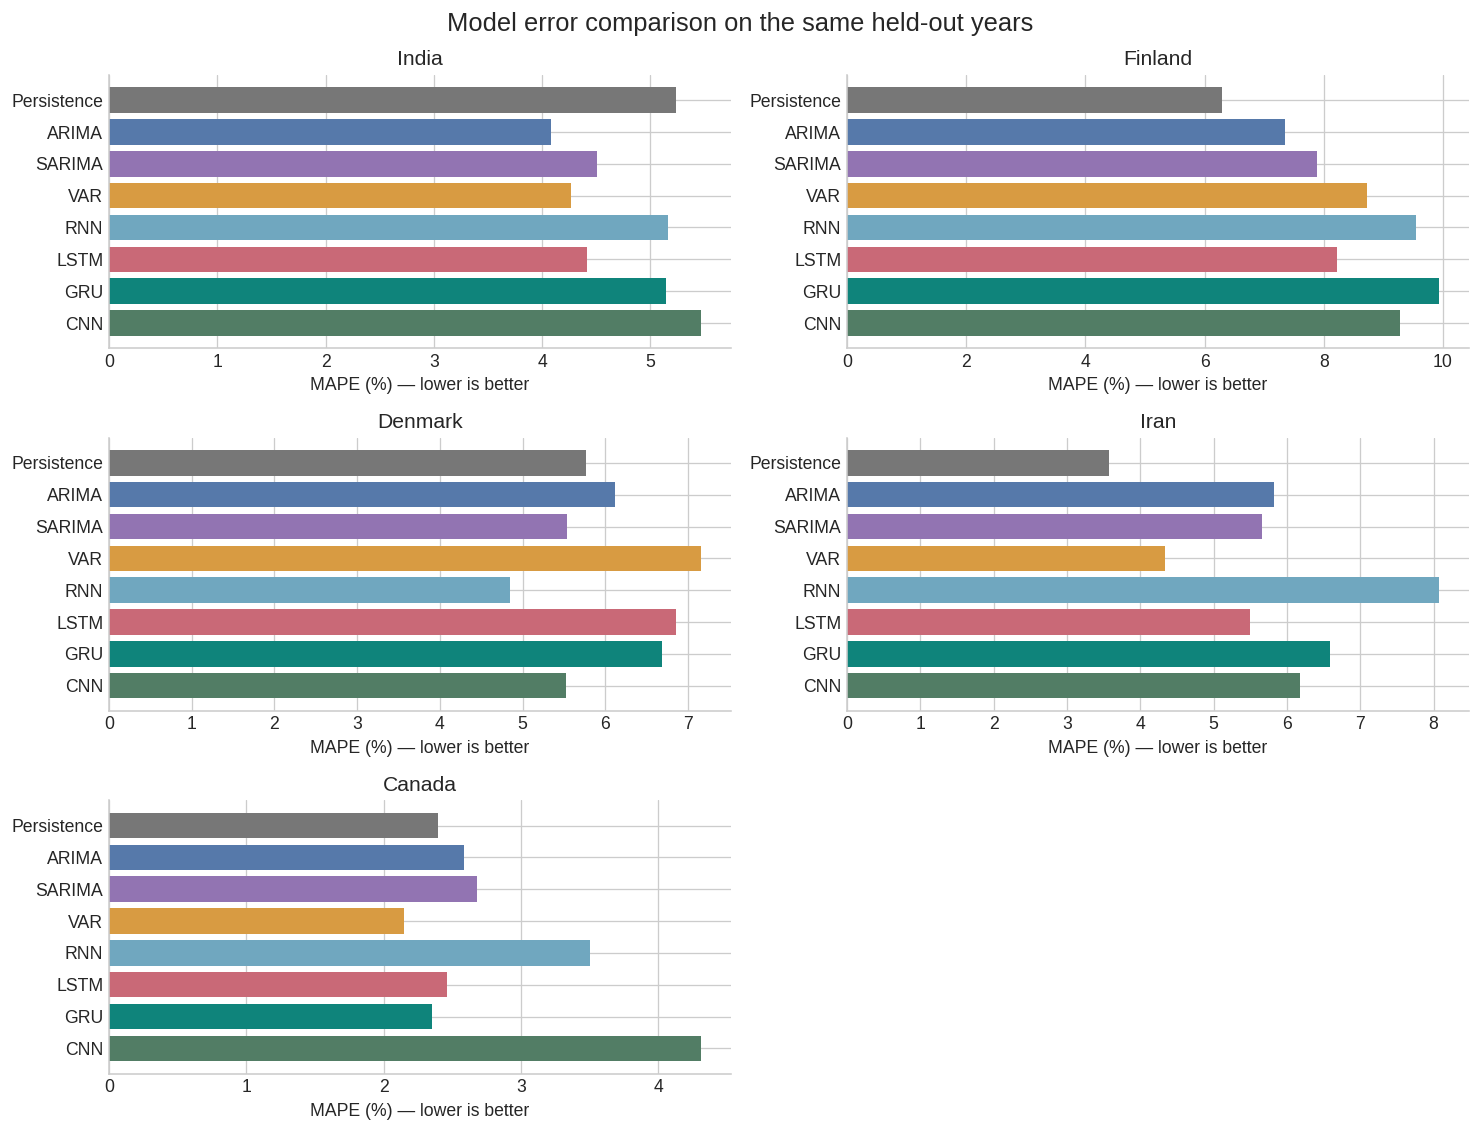

In [ ]:
# Compare all eight approaches at a glance, using country-scale-independent MAPE.
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for ax, country in zip(axes.flat, COUNTRIES):
    p = metrics[metrics.Country.eq(country)].set_index("Model").reindex(ALL_MODELS)
    ax.barh(p.index, p["MAPE (%)"], color=[MODEL_COLORS[m] for m in p.index])
    ax.invert_yaxis()
    ax.set(title=country, xlabel="MAPE (%) — lower is better")
axes.flat[-1].axis("off")
fig.suptitle("Model error comparison on the same held-out years", fontsize=16)
plt.tight_layout(); plt.show()

## 8. Actual vs predicted curves: every model, every country

Each country gets eight panels (seven requested methods plus persistence). Black is the true held-out series. The colored dashed curve is the model prediction. All panels for a country have the same axis limits so curves can be compared directly. Values in these panels are genuinely out-of-sample one-step guesses.

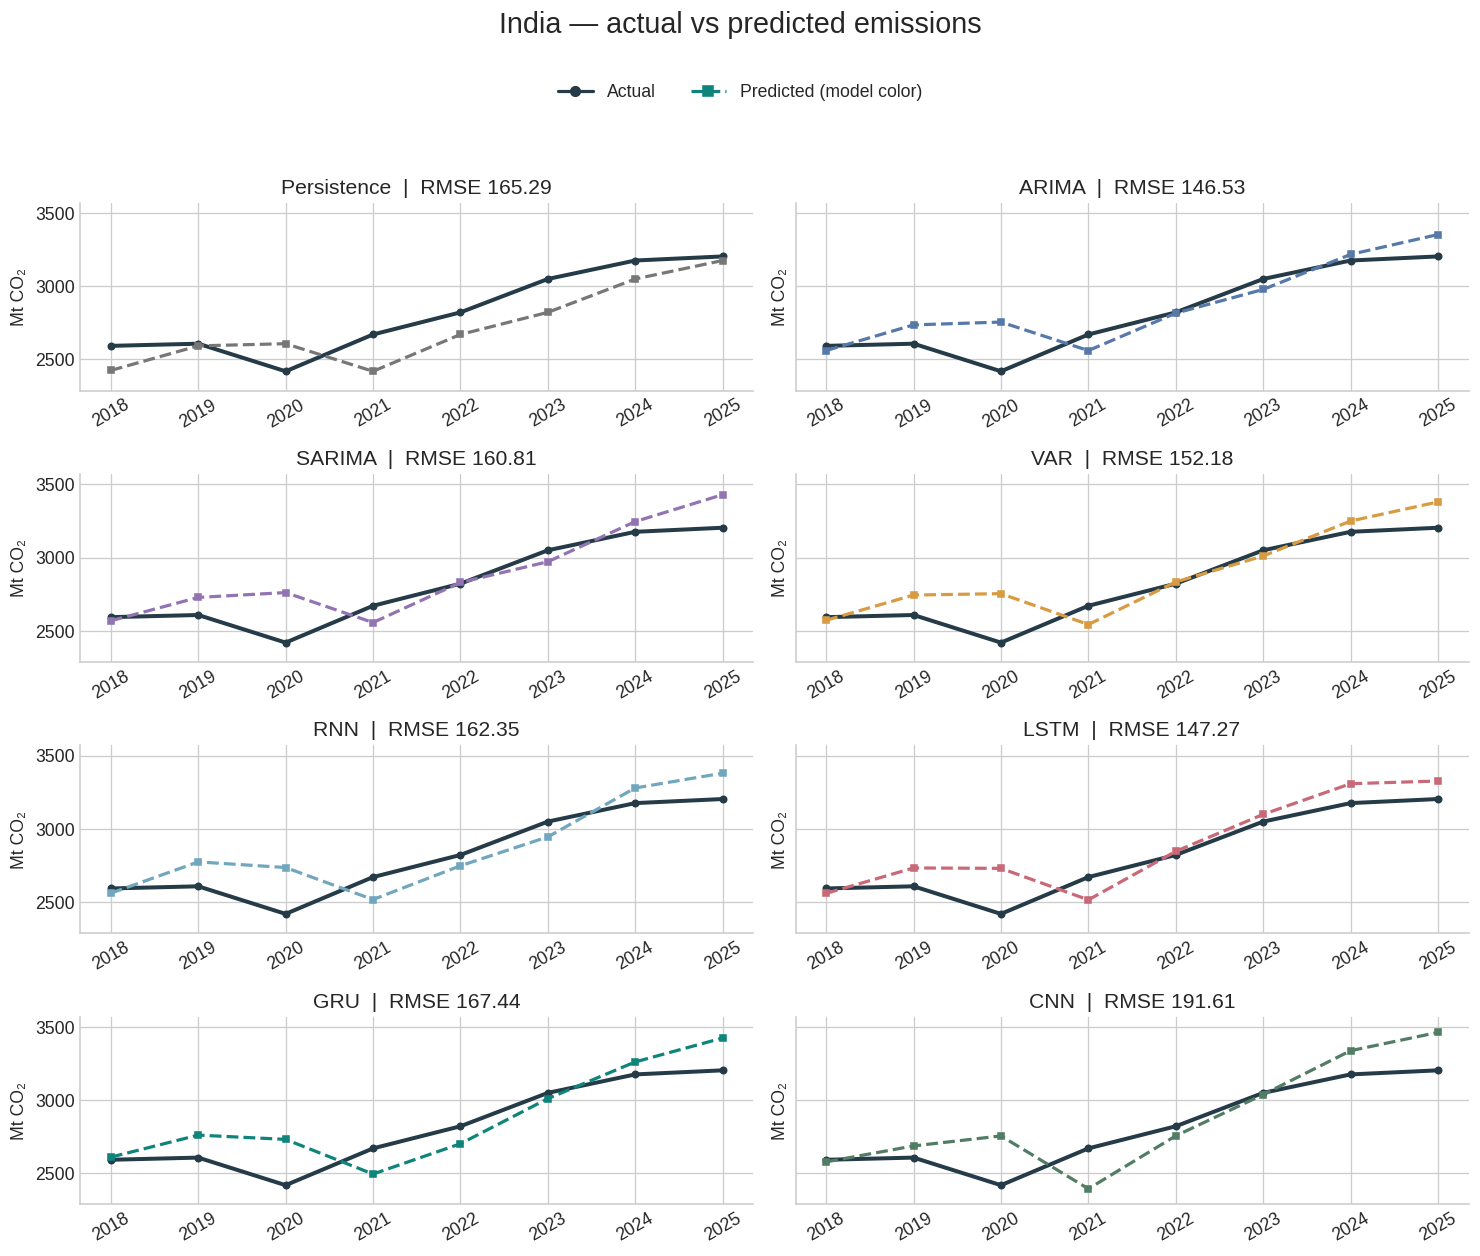

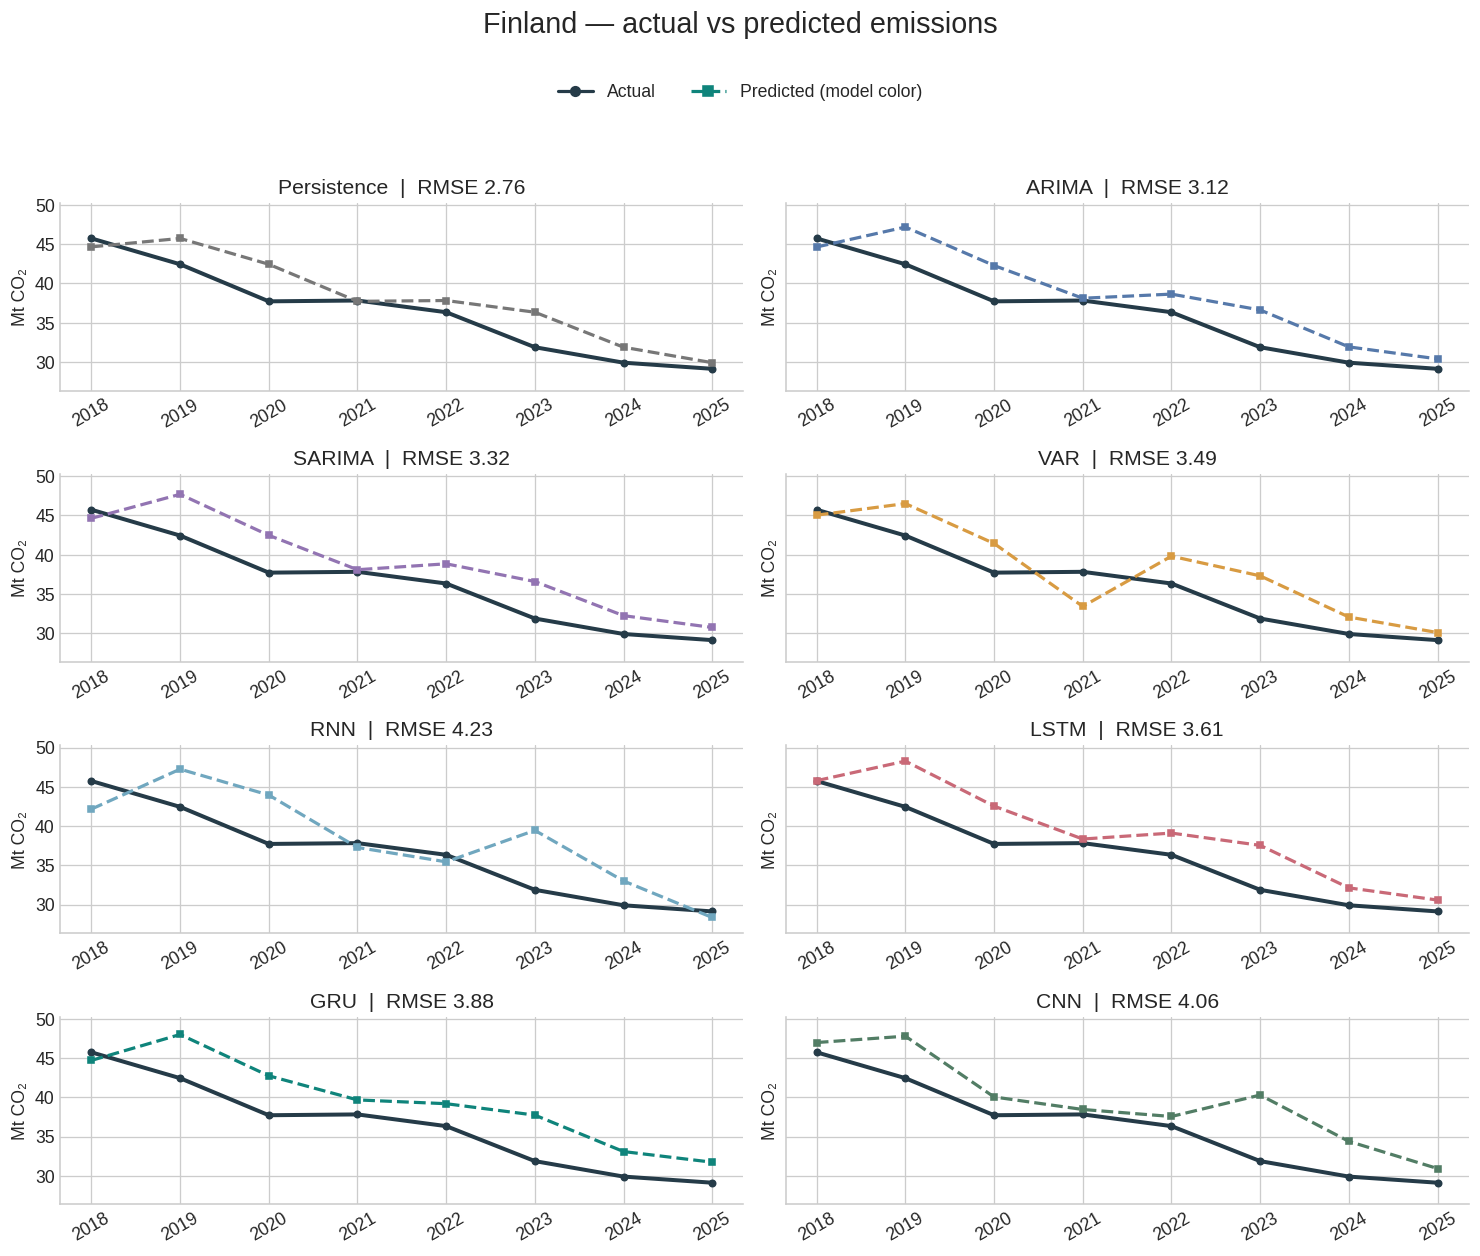

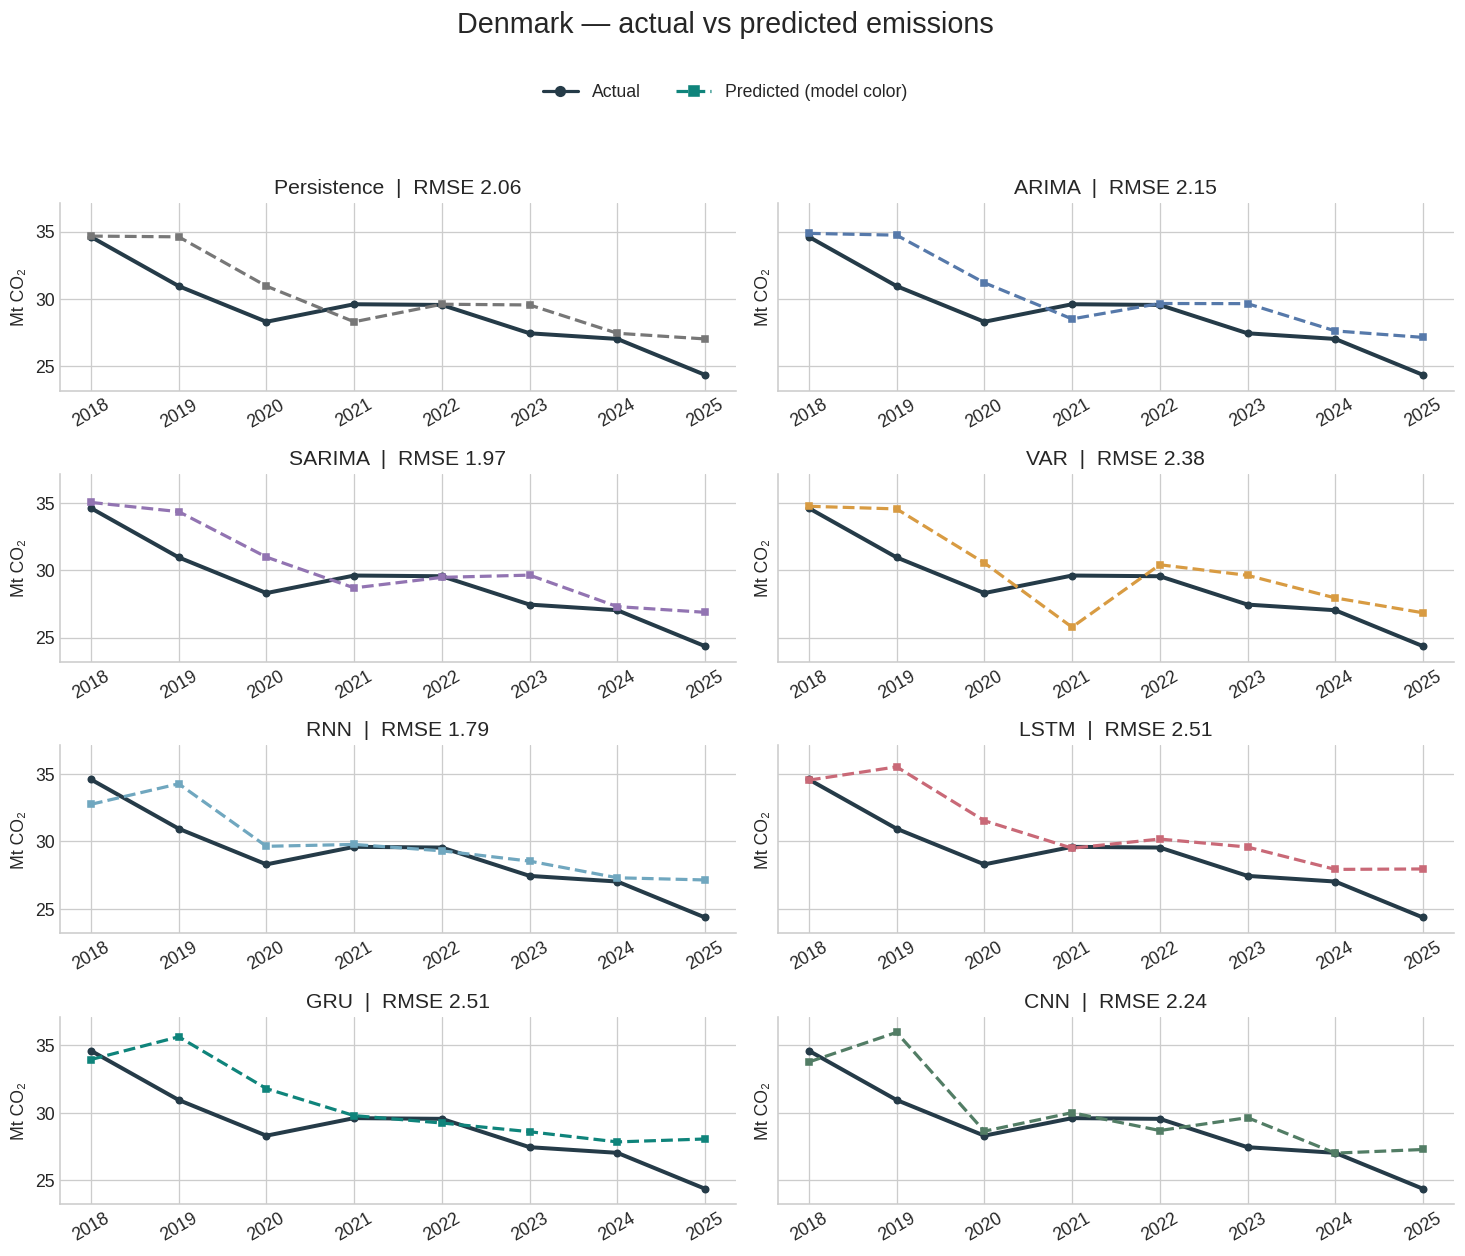

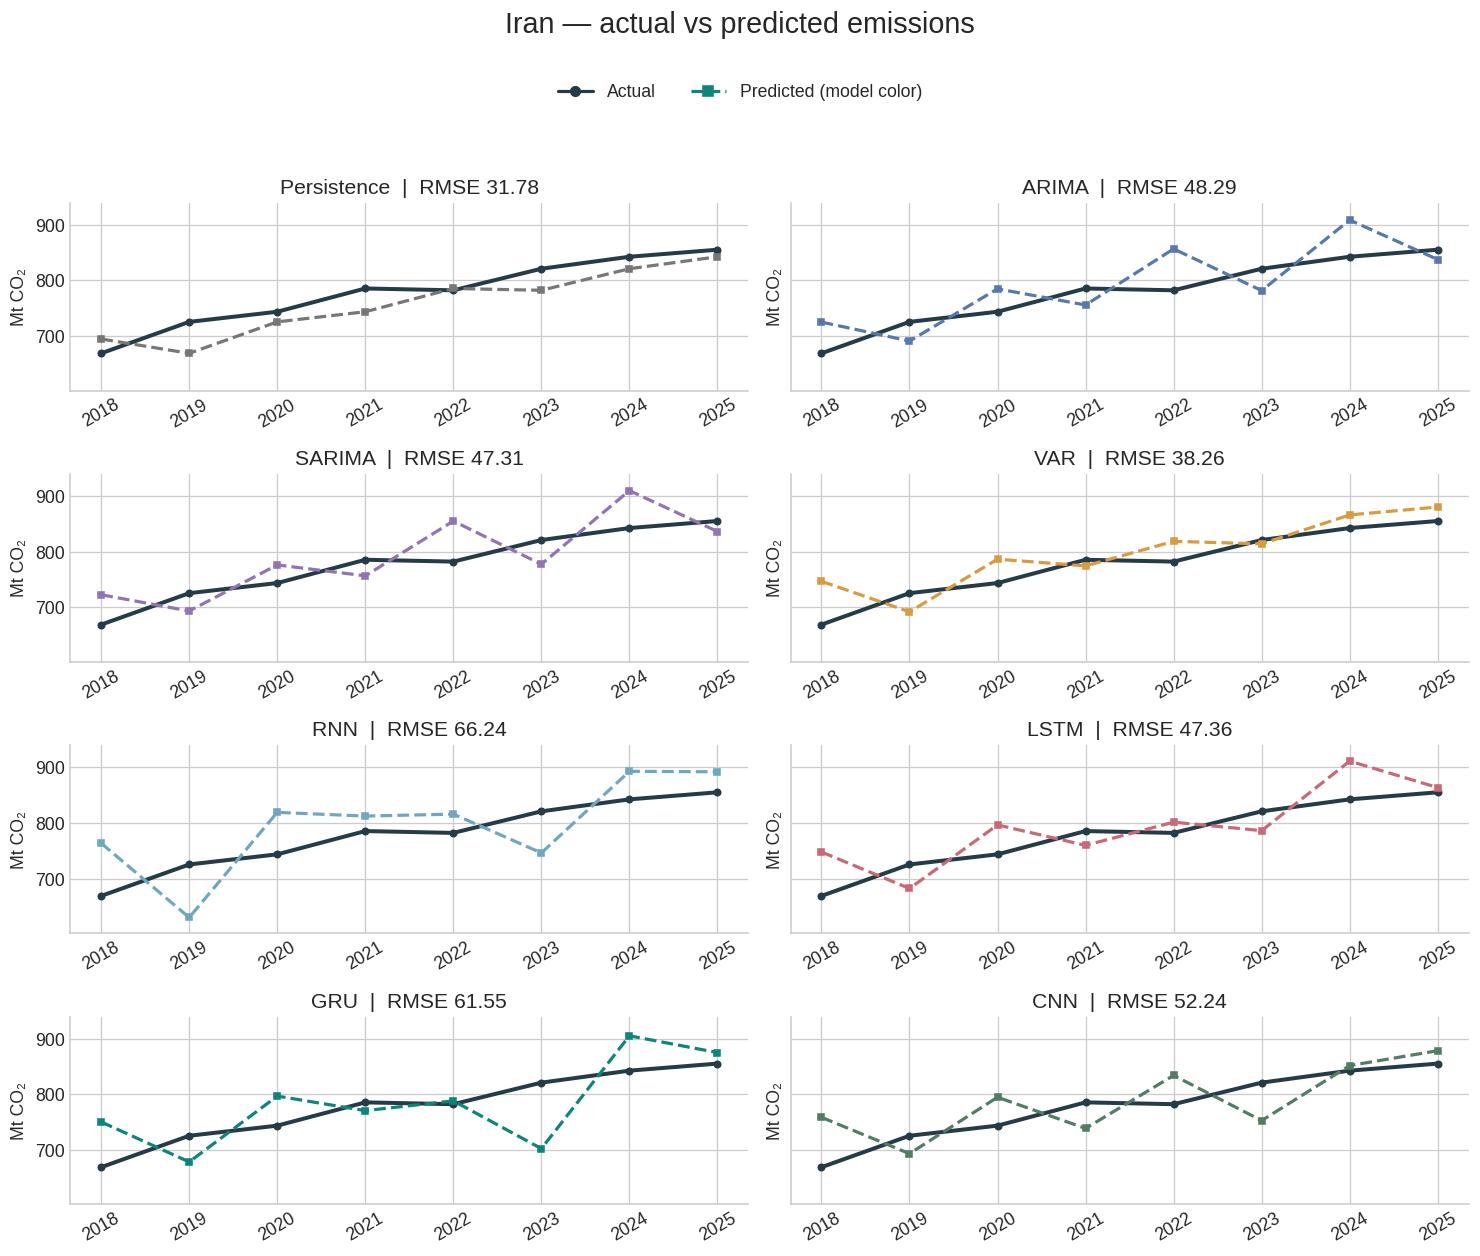

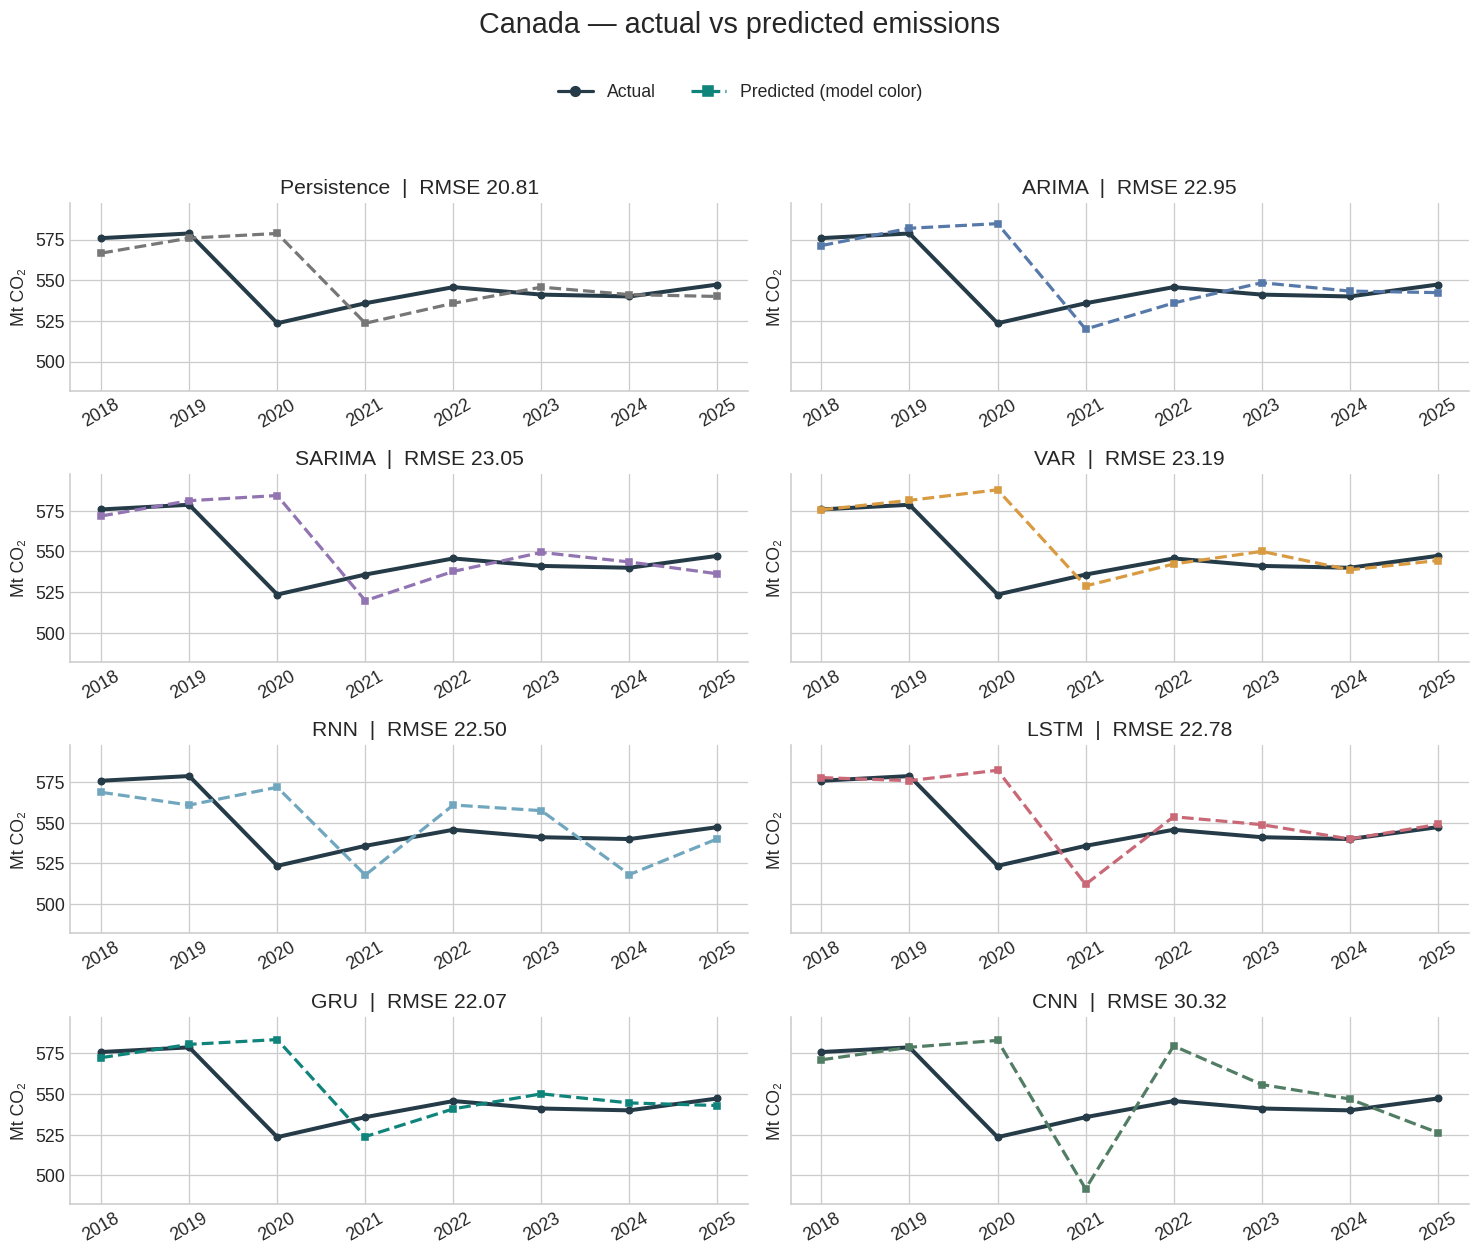

In [ ]:
from matplotlib.lines import Line2D

for country in COUNTRIES:
    actual = data[country].iloc[split:].to_numpy()
    all_curves = [actual] + [predictions[(country,m)] for m in ALL_MODELS
                              if (country,m) in predictions]
    ymin = min(np.min(a) for a in all_curves)
    ymax = max(np.max(a) for a in all_curves)
    pad = max((ymax-ymin)*.10, 1e-6)
    fig, axs = plt.subplots(4, 2, figsize=(13, 11), sharex=True, sharey=True)
    for ax, name in zip(axs.flat, ALL_MODELS):
        ax.plot(test_years, actual, color="#253B48", lw=2.5, marker="o", ms=4)
        pred = predictions.get((country,name))
        if pred is None:
            ax.text(.5,.5,"Model failed — see training log",transform=ax.transAxes,
                    ha="center", color="#C96F61")
            title = name
        else:
            ax.plot(test_years, pred, "--s", color=MODEL_COLORS[name], lw=2, ms=3.5)
            rmse = calculate_metrics(actual,pred)["RMSE"]
            title = f"{name}  |  RMSE {rmse:.2f}"
        ax.set(title=title, ylim=(max(0,ymin-pad),ymax+pad), ylabel=UNIT)
        ax.tick_params(axis="x", labelbottom=True, labelrotation=30)
    fig.legend(handles=[Line2D([0],[0],color="#253B48",marker="o",lw=2,label="Actual"),
                        Line2D([0],[0],color="#0F847B",ls="--",marker="s",lw=2,label="Predicted (model color)")],
               loc="upper center", bbox_to_anchor=(.5,.945), ncol=2, frameon=False)
    fig.suptitle(f"{country} — actual vs predicted emissions", fontsize=18, y=.99)
    fig.tight_layout(rect=[0,0,1,.91]); plt.show()

## 9. Predict the next year for each country

We now retrain using **all available observed years**, including the previously held-out years. This is a normal final-model step after evaluation. We forecast the next year with no known observation in this downloaded dataset. The estimates are not observed emissions and cannot yet have error scores.

All seven forecasts are presented, along with the simple persistence baseline. The GRU trained on India's full history will be reused in our experiment.

In [ ]:
next_year = int(end_year+1)
future = {}
final_gru_india = None
try:
    joint_full = fit_var(values)
    var_future = var_one_step(joint_full, values)
except Exception as exc:
    var_future = None
    failures.append({"Country":"All countries","Model":"VAR","Stage":"Future","Message":str(exc)})
    print("VAR future forecast failed:", exc)

for j,country in enumerate(COUNTRIES):
    print(f"Refitting on all observed data: {country}", flush=True)
    series = values[:,j]
    future[(country,"Persistence")] = float(series[-1])
    if var_future is not None:
        future[(country,"VAR")] = float(var_future[j])
    for name in ["ARIMA","SARIMA",*NEURAL_MODELS]:
        try:
            if name in NEURAL_MODELS:
                bundle = fit_neural(name, series)
                future[(country,name)] = neural_one_step(bundle, series)
                if country == "India" and name == "GRU":
                    final_gru_india = bundle
            else:
                future[(country,name)] = stat_one_step(fit_statistical(name, series))
        except Exception as exc:
            failures.append({"Country":country,"Model":name,"Stage":"Future","Message":str(exc)})
            print(f"  {name} failed: {exc}")

future_table = pd.DataFrame(
    [{"Country":c, "Model":m, "Forecast year":next_year,
      "Prediction":future.get((c,m),np.nan)}
     for c in COUNTRIES for m in ALL_MODELS])
print(f"Estimated emissions for {next_year} ({UNIT}):")
display(future_table.pivot(index="Country",columns="Model",values="Prediction")
        .reindex(index=COUNTRIES,columns=ALL_MODELS).round(3))
if failures:
    display(pd.DataFrame(failures))

Refitting on all observed data: India
Refitting on all observed data: Finland
Refitting on all observed data: Denmark
Refitting on all observed data: Iran
Refitting on all observed data: Canada
Estimated emissions for 2026 (Mt CO₂):


Model,Persistence,ARIMA,SARIMA,VAR,RNN,LSTM,GRU,CNN
Country,,,,,,,,
India,3203.406,3376.385,3381.703,3363.108,3374.753,3473.715,3475.059,3465.003
Finland,29.122,29.254,29.249,28.647,27.730,29.244,28.590,29.514
Denmark,24.356,24.330,24.585,24.038,23.129,24.467,24.381,22.390
Iran,855.278,925.853,925.809,912.284,878.088,887.902,894.366,871.959
Canada,547.319,550.112,551.777,552.292,557.870,554.650,550.935,550.481


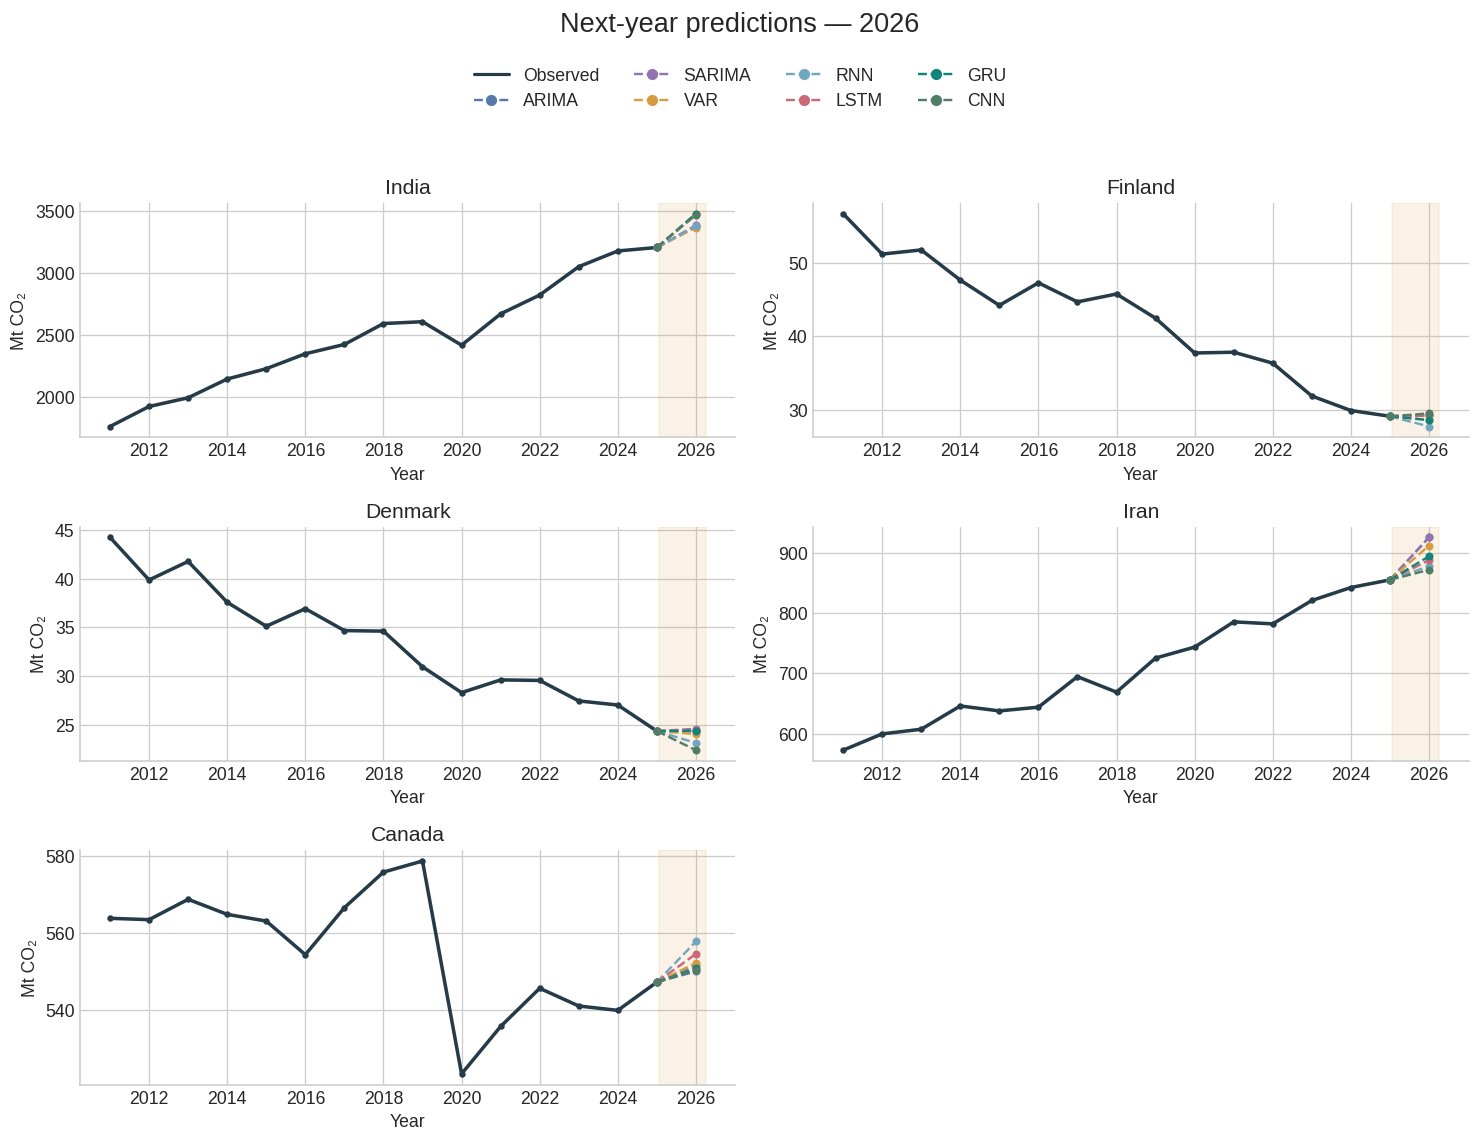

In [ ]:
fig, axs = plt.subplots(3,2,figsize=(13,10))
for ax,country in zip(axs.flat,COUNTRIES):
    recent = data[country].tail(15)
    ax.plot(recent.index, recent, color="#253B48", lw=2.2, marker="o", ms=3, label="Observed")
    for name in MODELS:
        if (country,name) in future:
            ax.plot([end_year,next_year],[recent.iloc[-1],future[(country,name)]],
                    "--o", color=MODEL_COLORS[name], label=name, lw=1.5, ms=4)
    ax.axvspan(end_year+.05,next_year+.25, color="#D99C3D", alpha=.12)
    ax.set(title=country,xlabel="Year",ylabel=UNIT)
axs.flat[-1].axis("off")
handles, labels = axs.flat[0].get_legend_handles_labels()
# Use a stable model legend even if a model failed for the first country.
fig.legend(handles=[Line2D([0],[0],color="#253B48",lw=2,label="Observed")] +
                   [Line2D([0],[0],color=MODEL_COLORS[m],ls="--",marker="o",label=m) for m in MODELS],
           loc="upper center",bbox_to_anchor=(.5,.955),ncol=4,frameon=False)
fig.suptitle(f"Next-year predictions — {next_year}",fontsize=17,y=.99)
plt.tight_layout(rect=[0,0,1,.90]); plt.show()

## 10. Live experiment: what if India's recent CO₂ emissions change?

**The audience can now participate!** We keep the final fitted India GRU and its scaling unchanged and modify the recent input history. This illustrates how a prediction responds to new observations.

Example: imagine the last three recorded years had 20% lower CO₂ emissions. What would the same GRU forecast next? Compare against the original history and against a hypothetical increase. The original public data are never changed.

This is a **sensitivity experiment**, not proof that a policy will reduce emissions by a specified amount. The modified history is fictional. Because the GRU learns from changes, modifying a historical value changes the growth rates around it and may change the forecast in unexpected directions. Future years after the first are recursive forecasts (the next prediction uses the preceding predicted value), so uncertainty accumulates.

In [ ]:
# ---- LIVE DEMO SETTINGS ----
# Change these values and rerun this cell and the next cell.
CHANGE_PERCENT = -20    # Try -10, -20, 0, +10 or +20
YEARS_TO_CHANGE = 3     # Change the last 1, 2, 3... observed years
SCENARIO_HORIZON = 3    # Show next 3 years; only forecast #1 is one-step

if final_gru_india is None:
    raise RuntimeError("India GRU is not trained. Run Step 9 first.")
if not -100 < CHANGE_PERCENT <= 100:
    raise ValueError("Choose a change greater than -100% and at most +100%.")
if not 1 <= YEARS_TO_CHANGE <= LOOKBACK:
    raise ValueError(f"Choose 1 to {LOOKBACK} years so the edit is in the GRU input window.")
if not 1 <= SCENARIO_HORIZON <= 10:
    raise ValueError("Choose a horizon between 1 and 10.")

original = data["India"].copy()
modified = original.copy()   # Critical: never overwrite the actual data.
modified.iloc[-YEARS_TO_CHANGE:] *= (1 + CHANGE_PERCENT/100)

def forecast_recursive(bundle, series, horizon):
    history = list(np.asarray(series,dtype=float))
    preds = []
    for _ in range(horizon):
        p = neural_one_step(bundle, np.asarray(history))
        preds.append(p)
        history.append(p)
    return np.array(preds)

forecast_years = np.arange(next_year,next_year+SCENARIO_HORIZON)
original_future = forecast_recursive(final_gru_india, original, SCENARIO_HORIZON)
modified_future = forecast_recursive(final_gru_india, modified, SCENARIO_HORIZON)
changed_years = original.index[-YEARS_TO_CHANGE:]
print(f"Modified {changed_years[0]}–{changed_years[-1]} by {CHANGE_PERCENT:+g}% (hypothetical).")
print("Original data vs modified inputs:")
display(pd.DataFrame({"Observed":original.loc[changed_years],
                      "Hypothetical":modified.loc[changed_years]}).round(3))
scenario_table = pd.DataFrame({"Year":forecast_years,
                              "Original GRU forecast":original_future,
                              "Modified-input GRU forecast":modified_future,
                              "Difference":modified_future-original_future,
                              "Difference (%)":100*(modified_future/original_future-1)})
display(scenario_table.round(3))
print(f"Next-year estimate: {original_future[0]:.2f} → {modified_future[0]:.2f} {UNIT}")
print("These results are conditional model responses, not causal policy estimates.")

Modified 2023–2025 by -20% (hypothetical).
Original data vs modified inputs:


,Observed,Hypothetical
year,,
2023,3049.351,2439.481
2024,3175.552,2540.442
2025,3203.406,2562.725


,Year,Original GRU forecast,Modified-input GRU forecast,Difference,Difference (%)
0,2026,3475.059,2867.354,-607.705,-17.488
1,2027,3533.040,3168.008,-365.032,-10.332
2,2028,3592.321,3545.519,-46.803,-1.303


Next-year estimate: 3475.06 → 2867.35 Mt CO₂
These results are conditional model responses, not causal policy estimates.


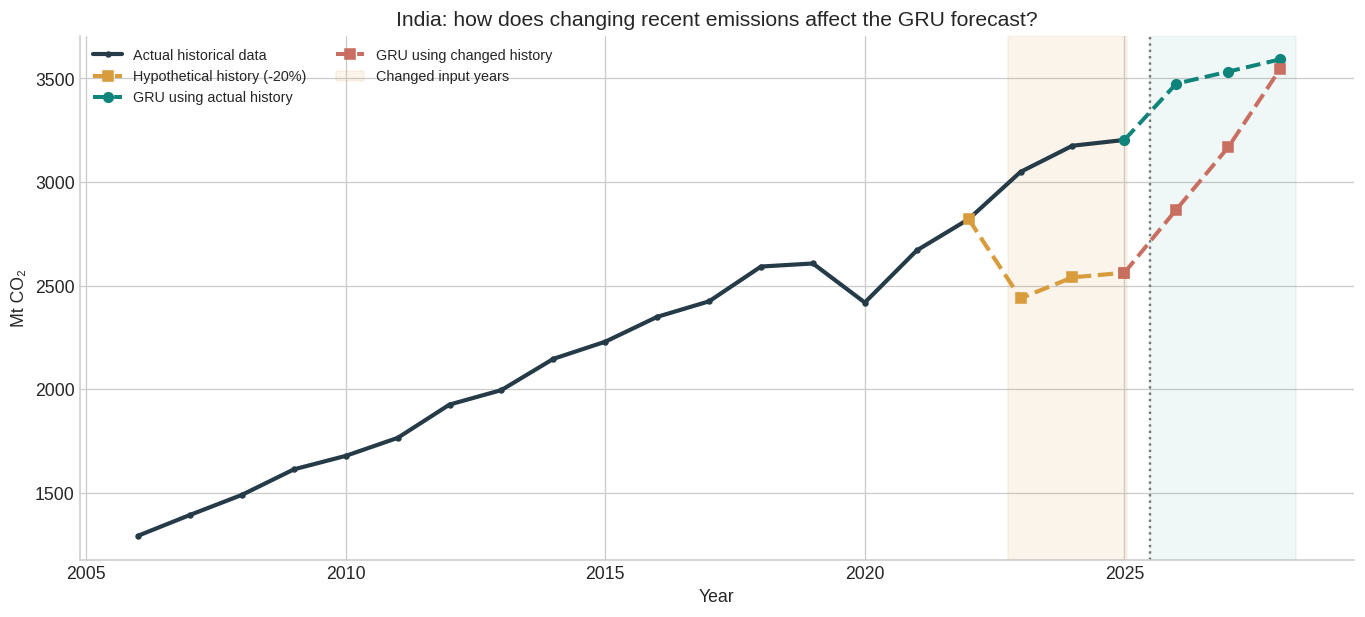

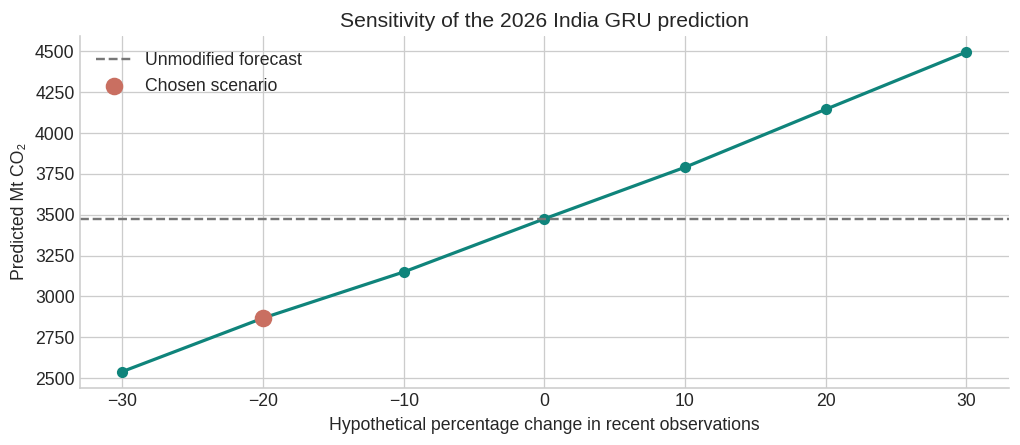

In [ ]:
fig, ax = plt.subplots(figsize=(12,5.5))
recent = original.tail(20)
sim_recent = modified.loc[recent.index]
ax.plot(recent.index,recent,color="#253B48",lw=2.6,marker="o",ms=3,label="Actual historical data")
# Draw the hypothetical history only where the edited inputs begin.
edge_year = int(changed_years[0])-1
scenario_history = sim_recent.loc[sim_recent.index>=edge_year]
ax.plot(scenario_history.index,scenario_history,color="#D99C3D",lw=2.6,ls="--",
        marker="s",label=f"Hypothetical history ({CHANGE_PERCENT:+g}%)")
ax.plot(np.r_[end_year,forecast_years],np.r_[original.iloc[-1],original_future],
        color="#0F847B",lw=2.5,ls="--",marker="o",label="GRU using actual history")
ax.plot(np.r_[end_year,forecast_years],np.r_[modified.iloc[-1],modified_future],
        color="#C96F61",lw=2.5,ls="--",marker="s",label="GRU using changed history")
ax.axvspan(changed_years[0]-.25,end_year+.05,color="#D99C3D",alpha=.10,label="Changed input years")
ax.axvline(end_year+.5,color="#777777",ls=":")
ax.axvspan(end_year+.5,forecast_years[-1]+.3,color="#0F847B",alpha=.06)
ax.set(title="India: how does changing recent emissions affect the GRU forecast?",
       xlabel="Year",ylabel=UNIT)
ax.legend(ncol=2,loc="upper left",fontsize=9); plt.tight_layout(); plt.show()

# Compare several alternative changes to the same input years, without retraining.
percentages = sorted(set([-30,-20,-10,0,10,20,30,CHANGE_PERCENT]))
effects = []
for pct in percentages:
    candidate = original.copy()
    candidate.iloc[-YEARS_TO_CHANGE:] *= 1+pct/100
    effects.append(neural_one_step(final_gru_india,candidate))
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(percentages,effects,"-o",color="#0F847B",lw=2)
ax.axhline(original_future[0],ls="--",color="#777777",label="Unmodified forecast")
ax.scatter([CHANGE_PERCENT],[modified_future[0]],s=100,color="#C96F61",zorder=4,label="Chosen scenario")
ax.set(title=f"Sensitivity of the {next_year} India GRU prediction",
       xlabel="Hypothetical percentage change in recent observations",
       ylabel=f"Predicted {UNIT}")
ax.legend(); plt.tight_layout(); plt.show()

### Discuss with the audience

1. If the input falls by 20%, does the forecast also fall by exactly 20%? Why might a learned model react differently?
2. Does this prove a government policy caused an emissions reduction? **No**. We modified model inputs, not the underlying physical or economic system.
3. What else would a realistic environmental digital twin require? Additional covariates, verified measurement streams, a validated process or scenario model, uncertainty estimates and a feedback loop.
4. Which forecasting model actually performed best for each country? Did deep learning beat persistence? Why might a simpler method work better with only a few decades of annual records?

## 11. Save the outputs (optional)

The next cell exports the comparison table, the individual actual/predicted values, the next-year forecasts and India's scenario table. In Colab, the CSVs appear in the Files panel; right-click a file and choose Download.

In [ ]:
metrics.to_csv("model_comparison_rmse_mape_mae.csv", index=False)
all_prediction_rows = []
for country in COUNTRIES:
    for name in ALL_MODELS:
        pred = predictions.get((country,name),np.full(TEST_YEARS,np.nan))
        for year,actual,predicted in zip(test_years,data[country].iloc[split:],pred):
            all_prediction_rows.append({"Country":country,"Model":name,"Year":year,
                                        "Actual":actual,"Predicted":predicted,"Unit":UNIT})
pd.DataFrame(all_prediction_rows).to_csv("actual_vs_predicted_all_countries.csv",index=False)
future_table.assign(Unit=UNIT).to_csv("next_year_forecasts.csv",index=False)
scenario_table.assign(Unit=UNIT).to_csv("india_gru_sensitivity.csv",index=False)
if failures:
    pd.DataFrame(failures).to_csv("model_diagnostics.csv",index=False)
print("Saved 4 result CSVs, the input snapshot, and any model diagnostics.")

Saved 4 result CSVs, the input snapshot, and any model diagnostics.


---
### Key takeaway

Forecasting models learn patterns from historical observations. Their value is measured by honest tests on later years, not by their complexity. Changing input history provides insight into **model sensitivity**, while actual environmental impacts require additional scientific evidence.

**Further reading:** [OWID CO₂ data](https://github.com/owid/co2-data), [statsmodels time-series forecasting](https://www.statsmodels.org/stable/tsa.html), [PyTorch neural-network documentation](https://docs.pytorch.org/docs/stable/nn.html).